# 🚀 Practice Day 30

**📅 Date:** 2026-10-10  
📁 Category: Phase 1 · NumPy 기초 (Round 3/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice vectorized NumPy operations by implementing a tiered (누진) electricity billing formula across many households at once
  (누진 전기요금제를 벡터화된 NumPy 연산으로 구현하며 배열 연산 연습하기)
- Find how bills are distributed, which usage tier most households fall into, and which households pay the most/least
  (요금이 어떻게 분포하는지, 대부분의 가구가 어느 사용량 구간에 속하는지, 요금을 가장 많이/적게 내는 가구는 어디인지 파악하기)

---
# 📂 Dataset

**Dataset Name:** 가구별 월간 전기요금 (누진제 적용) / Household Monthly Electricity Bills (Tiered Rate)

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 50 households × 4 months (Jan–Apr 2024) of monthly electricity usage — 200 rows, single table. Only `usage_kwh` is included; the bill (USD) needs to be computed using a 3-tier progressive rate structure via vectorized array operations. Winter months (Jan-Feb) run higher due to heating. Clean — no missing values or duplicates.

**Rate structure / 요금 구조:**
- Base fee (기본요금): ≤200kWh → $0.91 · 200–400kWh → $1.60 · >400kWh → $7.30
- Usage rate (전력량요금): Tier 1 (0–200kWh) $0.120/kWh · Tier 2 (200–400kWh portion) $0.214/kWh · Tier 3 (above 400kWh portion) $0.307/kWh
- Bill = base fee + (Tier1 usage × 0.120) + (Tier2 usage × 0.214) + (Tier3 usage × 0.307)

(50가구 × 4개월(2024년 1~4월)의 월간 전력 사용량 데이터입니다(단일 테이블, 200행). usage_kwh만 포함되어 있고, 요금(USD)은 위 3단계 누진 요금제를 벡터화 연산으로 직접 계산해야 합니다. 겨울(1~2월)에는 난방으로 사용량이 더 높습니다. 결측치·중복 없이 깨끗합니다.)

## Dataset Preview

In [10]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate monthly usage_kwh for 50 households over 4 months (bill is NOT precomputed) ---
n_households = 50
months = ['2024-01', '2024-02', '2024-03', '2024-04']
household_ids = [f'H{str(i).zfill(3)}' for i in range(1, n_households + 1)]

rows = []
for hid in household_ids:
    base_usage = rng.normal(280, 100)
    for m in months:
        seasonal = 1.25 if m in ('2024-01', '2024-02') else 1.0  # winter heating bump
        usage = max(50, rng.normal(base_usage * seasonal, 40))
        rows.append({'household_id': hid, 'month': m, 'usage_kwh': round(usage, 1)})

df = pd.DataFrame(rows)

df.head(10)


,household_id,month,usage_kwh
0,H001,2024-01,346.5
1,H001,2024-02,418.1
2,H001,2024-03,348.1
3,H001,2024-04,232.4
4,H002,2024-01,192.3
5,H002,2024-02,174.6
6,H002,2024-03,149.1
7,H002,2024-04,115.7
8,H003,2024-01,491.0
9,H003,2024-02,462.6


## Dataset Information

In [11]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   household_id  200 non-null    str    
 1   month         200 non-null    str    
 2   usage_kwh     200 non-null    float64
dtypes: float64(1), str(2)
memory usage: 4.8 KB

Shape: (200, 3)


,household_id,month,usage_kwh
count,200,200,200.000000
unique,50,4,NaN
top,H001,2024-01,NaN
freq,4,50,NaN
mean,NaN,NaN,310.850500
std,NaN,NaN,114.191679
min,NaN,NaN,99.100000
25%,NaN,NaN,231.950000
50%,NaN,NaN,292.800000
75%,NaN,NaN,392.225000


---
# ❓ Business Questions

1. **(Analysis)** Using the tiered rate structure above, what is each household-month's electricity bill?
   (위 누진 요금 구조를 적용하면, 가구별·월별 전기요금은 각각 얼마인가?)
2. **(Analysis)** How many household-months fall into each usage tier (Tier 1: ≤200kWh, Tier 2: 200-400kWh, Tier 3: >400kWh)?
   (각 사용량 구간(Tier1/2/3)에 속하는 가구-월은 각각 몇 건인가?)
3. **(Analysis)** Which household-month paid the most, and which paid the least?
   (요금을 가장 많이/적게 낸 가구-월은?)
4. **(Visualization)** Show the distribution of monthly bills across all households.
   (전체 가구의 월별 요금 분포는 어떤 모습인가?)
5. **(Visualization)** Show the relationship between usage and bill — where does the tiered structure become visible?
   (사용량과 요금의 관계를 보면, 누진 구조가 어디서 드러나는가?)

---
# 🔍 Data Cleaning Check


In [12]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
household_id    0
month           0
usage_kwh       0
dtype: int64

Duplicate rows: 0

Dtypes
household_id        str
month               str
usage_kwh       float64
dtype: object

Column names
['household_id', 'month', 'usage_kwh']

Text columns — unique counts
household_id    50
month            4
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** Using the tiered rate structure, what is each household-month's electricity bill? (누진 요금 구조 적용 시 가구별·월별 요금은?)

**Result:** Each of the 200 rows has its own `bill_usd`. H001 in January is **$56.95** (346.5 kWh) and in April **$32.53** (232.4 kWh).
(200행마다 `bill_usd`가 하나씩 있음. H001 1월은 $56.95(346.5 kWh), 4월은 $32.53(232.4 kWh))

**Insight:** The same household is not one bill. H001's January bill is **$24.42** above its April bill because that month used more kWh.
(같은 가구도 요금이 하나가 아님. H001 1월 요금이 4월보다 $24.42 높음. 그달 사용량이 더 많아서)


In [13]:
# Question 1: compute bill_usd for every row using the tiered rate structure (vectorized - no row-by-row loop)

usage = df['usage_kwh'].to_numpy()

tier1 = np.minimum(usage, 200)
tier2 = np.clip(usage - 200, 0, 200)
tier3 = np.maximum(usage - 400, 0)

base = np.where(usage <= 200, 0.91, np.where(usage <= 400, 1.60, 7.30))

df['bill_usd'] = (base + tier1 * 0.120 + tier2 * 0.214 + tier3 * 0.307).round(2)
df[['household_id', 'month', 'usage_kwh', 'bill_usd']].head()

,household_id,month,usage_kwh,bill_usd
0,H001,2024-01,346.5,56.95
1,H001,2024-02,418.1,79.66
2,H001,2024-03,348.1,57.29
3,H001,2024-04,232.4,32.53
4,H002,2024-01,192.3,23.99


## Question 2

**Question:** How many household-months fall into each usage tier? (구간별 가구-월 건수는?)

**Result:** Tier 2 **115**, Tier 3 **47**, Tier 1 **38**.

**Insight:** Tier 2 is **115** of 200 rows. Most household-months sit between 200 and 400 kWh, so they pay the $1.60 base fee and the $0.214 rate on the slice above 200.
(200건 중 Tier 2가 115건. 대부분 200–400 kWh라서 기본요금 $1.60과, 200을 넘는 부분에 $0.214를 냄)


In [14]:
# Question 2: how many household-months fall into each usage tier

tier = np.select(
    [df['usage_kwh'] <= 200, df['usage_kwh'] <= 400],
    ['Tier 1', 'Tier 2'],
    default='Tier 3'
)
df['tier'] = tier
df['tier'].value_counts().reindex(['Tier 1', 'Tier 2', 'Tier 3'])

tier
Tier 1     38
Tier 2    115
Tier 3     47
Name: count, dtype: int64

## Question 3

**Question:** Which household-month paid the most, and which paid the least? (최고·최저 요금 가구-월은?)

**Result:** Highest is H032 in 2024-02, **$138.66** (610.3 kWh, Tier 3). Lowest is H020 in 2024-04, **$12.80** (99.1 kWh, Tier 1).
(최고는 H032 2024-02, $138.66(610.3 kWh, Tier 3). 최저는 H020 2024-04, $12.80(99.1 kWh, Tier 1))

**Insight:** The highest bill is **$125.86** above the lowest. H032 is past 400 kWh, so part of that usage is priced at $0.307. H020 stays inside Tier 1.
(최고 요금이 최저보다 $125.86 높음. H032는 400 kWh를 넘겨 일부가 $0.307이다. H020은 Tier 1 안에 있음)


In [18]:
# Question 3: highest and lowest bill_usd, and which household-month they belong to

highest = df.loc[df['bill_usd'].idxmax()]
lowest = df.loc[df['bill_usd'].idxmin()]
highest, lowest

(household_id       H032
 month           2024-02
 usage_kwh         610.3
 bill_usd         138.66
 tier             Tier 3
 Name: 125, dtype: object,
 household_id       H020
 month           2024-04
 usage_kwh          99.1
 bill_usd           12.8
 tier             Tier 1
 Name: 79, dtype: object)

---
# 📈 Visualization

**Chart 1:** Histogram — distribution of monthly bills (히스토그램: 월별 요금 분포)

*Interpretation:* The bars run from **$12.80** to **$138.66**. The right tail is the high Tier 3 bills, including H032 at **$138.66**.
(막대는 $12.80에서 $138.66까지. 오른쪽 꼬리는 Tier 3 고액이고, H032 $138.66이 그 끝)

---

**Chart 2:** Scatter plot — usage vs bill, showing the tiered structure (산점도: 사용량 vs 요금, 누진 구조 확인)

*Interpretation:* The points rise faster after the 200 kWh line and again after 400 kWh. H020 at 99.1 kWh is **$12.80**, left of 200. H032 at 610.3 kWh is **$138.66**, right of 400.
(점은 200 kWh 선 다음, 그리고 400 kWh 선 다음에 더 가팔라짐. H020 99.1 kWh는 $12.80으로 200 왼쪽. H032 610.3 kWh는 $138.66으로 400 오른쪽)


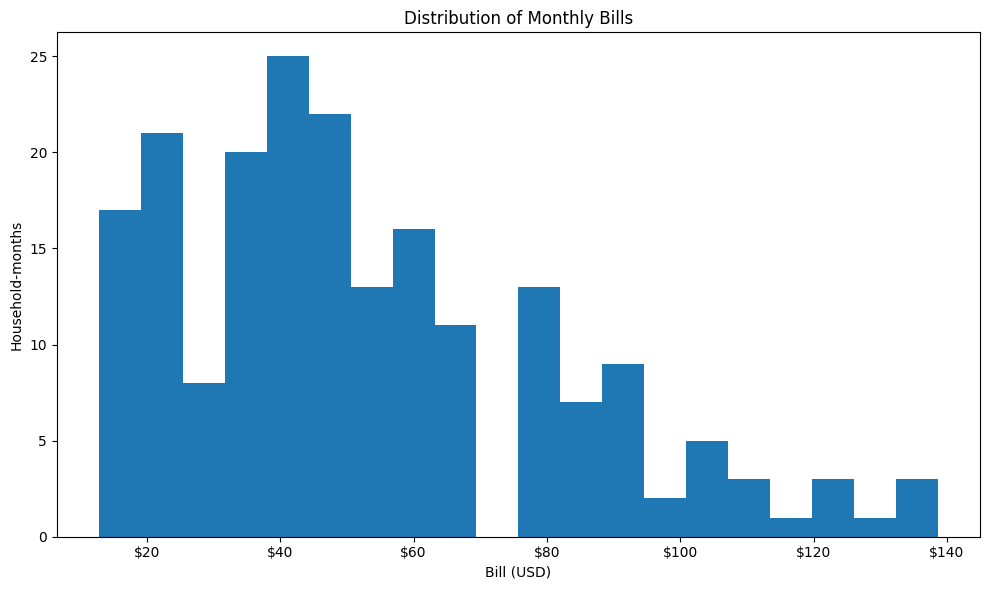

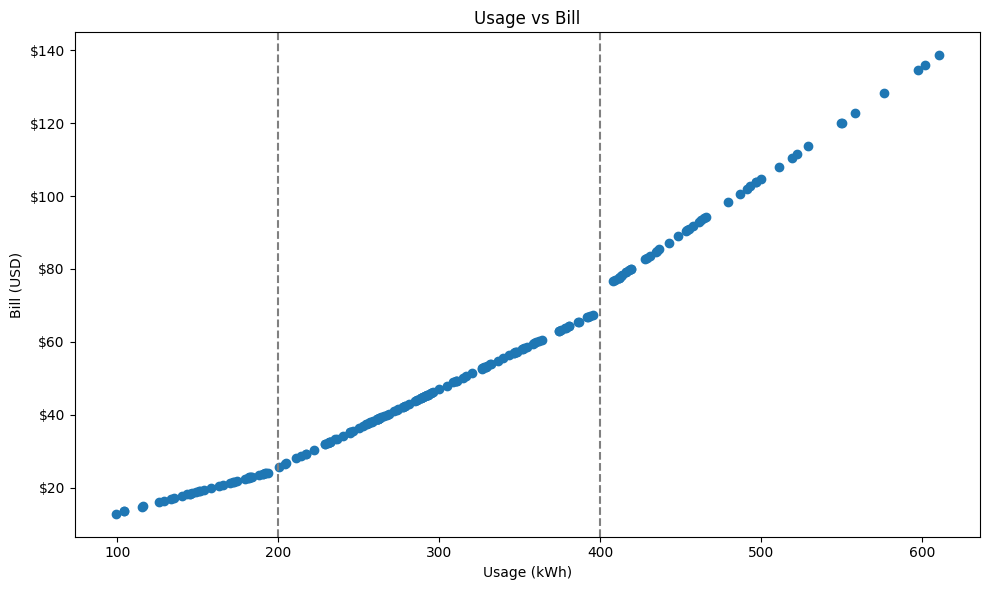

In [16]:
# Visualization
import matplotlib.pyplot as plt

# Chart 1: distribution of monthly bills (histogram)
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(df['bill_usd'], bins=20)
ax.xaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Distribution of Monthly Bills')
ax.set_xlabel('Bill (USD)')
ax.set_ylabel('Household-months')
plt.tight_layout()
plt.show()

# Chart 2: usage vs bill (scatter) - the tier structure should show up as slope changes at 200 and 400 kWh
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df['usage_kwh'], df['bill_usd'])
ax.axvline(200, color='gray', linestyle='--')
ax.axvline(400, color='gray', linestyle='--')
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Usage vs Bill')
ax.set_xlabel('Usage (kWh)')
ax.set_ylabel('Bill (USD)')
plt.tight_layout()
plt.show()

---
# 💼 Business Insights
*What did I discover?*

- A bill is one household in one month. H001's January bill is **$56.95** and its April bill is **$32.53**.
  (요금은 한 가구의 한 달. H001 1월은 $56.95, 4월은 $32.53)
- **115** of 200 household-months are Tier 2 (200–400 kWh). Tier 1 is **38** and Tier 3 is **47**.
  (200건 중 115건이 Tier 2(200–400 kWh). Tier 1은 38건, Tier 3은 47건)
- The highest bill is H032 in February, **$138.66**. The lowest is H020 in April, **$12.80**.
  (최고 요금은 H032 2월 $138.66. 최저는 H020 4월 $12.80)


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Watch months that cross 400 kWh. H032 in February used 610.3 kWh and the bill reached **$138.66**, with the slice above 400 priced at $0.307.
   (400 kWh를 넘는 달을 보기. H032 2월은 610.3 kWh, 요금 $138.66이고 400을 넘는 부분은 $0.307)
2. Most rows are already Tier 2 (**115** of 200). A small increase past 200 kWh switches that slice from $0.120 to $0.214.
   (대부분(200건 중 115건)이 이미 Tier 2. 200을 조금만 넘어도 그 부분은 $0.120이 아니라 $0.214)
3. Compare households on a single month, not a four-month total. H001's January and April bills differ by **$24.42**.
   (가구 비교는 4개월 합이 아니라 한 달 단위로. H001의 1월과 4월은 $24.42 차이)


---
# ❌ Mistakes
*What mistakes did I make today?*

- I did not see that the tier prices were in the Dataset section, so the bill looked like it had no inputs besides `usage_kwh`.
  (요금 단가가 Dataset 칸에 있는 걸 못 봐서, usage_kwh 말고는 계산 재료가 없어 보였음)
- I read "household-month" as one bill per household. Each row is one household in one month, so there are 200 bills.
  (가구별·월별을 가구당 요금 하나로 읽음. 한 행이 한 가구의 한 달이라 요금은 200개)


---
# ✅ What I Learned
*Today's biggest lesson*

- Split `usage_kwh` into three slices: up to 200, the next 200, and anything above 400. Each slice has its own price.
  (usage_kwh를 200까지, 그다음 200, 400 초과로 자름. 조각마다 단가가 다름)
- The base fee is one amount for the whole month, chosen from the month's total kWh. It is not multiplied by each slice.
  (기본요금은 그달 총 사용량으로 하나만 고름. 조각마다 곱하지 않음)
- `np.minimum`, `np.clip`, and `np.maximum` cut those slices for every row at once.
  (np.minimum, np.clip, np.maximum이 모든 행의 조각을 한 번에 자름)


---
# 🧠 Reflection

**What was difficult?**
Seeing how one kWh total becomes three priced slices plus one base fee.
(사용량 하나가 단가가 다른 세 조각과 기본요금 하나가 되는 과정)

**Why?**
The rate table prices the overflow differently from the first 200 kWh, and the base fee depends on the total, not on each slice.
(요금표가 처음 200 kWh와 넘는 부분의 단가를 다르게 두고, 기본요금은 조각이 아니라 총량으로 정해짐)

**How did I solve it?**
Walked a 250 kWh month: 200 at $0.120, 50 at $0.214, nothing at $0.307, plus the $1.60 base fee.
(250 kWh로 따라가 봄. 200은 $0.120, 50은 $0.214, $0.307은 없음, 기본요금 $1.60)

**What would I do differently next time?**
Read the rate table in the Dataset section before trying to average or group the usage column.
(사용량 열을 평균내거나 묶기 전에 Dataset의 요금표를 먼저 읽기)


---
# ⭐ Self Evaluation

**Understanding**
★★★★★★☆☆☆☆
The three slices, the single base fee, and a bill per household-month are clear after the example.
(세 조각, 기본요금 하나, 가구-월마다 요금 하나는 예시를 보고 이해함)

**Confidence**
★★★★★☆☆☆☆☆

**Difficulty**
★★★★★★★☆☆☆
The tier table itself was the hard part, not the NumPy functions.
(어려운 부분은 NumPy 함수가 아니라 누진 요금표 자체였음)


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 31 — data cleaning (Round 3/5)
  (데이터 클리닝 복습)
